# 2 · Distance fields: the Riemannian eikonal equation and fast marching

Notebook 1 showed that geodesics are the shortest motions under a metric $G$, but that
connecting two given points by shooting is awkward.  The trick of this paper is to
compute a **distance field** instead:

$$U(q)=\text{length of the shortest path from a source } q_s \text{ to } q .$$

Once $U$ is known, the geodesic from *any* $q$ back to $q_s$ is obtained for free by
following its gradient.  Everything in this notebook works in any space with any metric; we
use the plane of notebook 1 and the configuration space of the arm as examples.  In this notebook we:

1. write down the equation that $U$ satisfies (the Riemannian eikonal equation);
2. solve it on a grid with Riemannian fast marching (RFM);
3. turn the field into a **geodesic flow** and backtrack geodesics;
4. see why a grid solver is not the end of the story.

In [1]:
import time

import numpy as np
import torch
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80

from geodf import metrics, rfm, plotting as P
from geodf.robots import PlanarArm

torch.set_default_dtype(torch.float64)
pi = np.pi
arm = PlanarArm()
G = metrics.kinetic_energy(arm)

## 1. The Riemannian eikonal equation

Along any curve moving at unit speed ($\|\dot q\|_G=1$), the distance can grow at most at rate
one: $\dot U=\nabla U^\top\dot q\le\|\nabla U\|_{G^{-1}}\|\dot q\|_G$.  Along the geodesics leaving
$q_s$ it grows at exactly rate one, so the bound must be attained, which gives a first-order
PDE for $U$:

$$\big\|\nabla U(q)\big\|_{G^{-1}(q)}=\sqrt{\nabla U^\top G(q)^{-1}\nabla U}=1,\qquad U(q_s)=0.$$

Note the **inverse** metric: the gradient is a co-vector, so it is measured with $G^{-1}$.
For $G=I$ this is the classical eikonal equation $\|\nabla U\|=1$, whose solution is the
Euclidean distance.

## 2. Solving it on a grid: Riemannian fast marching

Fast marching is Dijkstra's algorithm for continuous distances.  Starting from the source,
a front of "accepted" grid points grows outwards, and every point is updated from its
already-known neighbours $y$ through

$$U(q)=\min_{y}\;U(y)+\|q-y\|_{G(q)} .$$

`geodf.rfm.solve` implements this update on a regular grid (with a wide stencil so that it is
accurate for strongly anisotropic metrics).  Instead of keeping an ordered front, it applies the
update to all grid points repeatedly until nothing changes, which converges to the same
solution and is simpler to vectorise.

### First, the plane with a costly region (notebook 1)
The solver only needs the metric as a function $q\mapsto G(q)$.  On the plane with the muddy disc,
the distance from a source on the left grows slowly outside the disc and fast inside it.  The
shortest paths (obtained by following the gradient of $U$, section 3) bend around the disc —
like light rays refracted by a lens of slow glass.

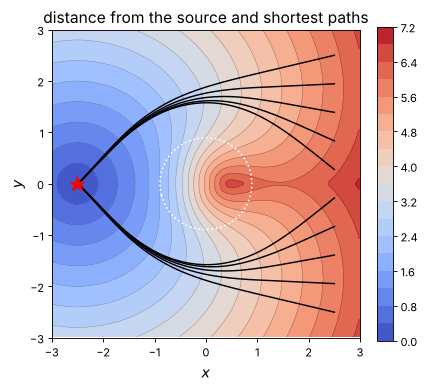

In [2]:
def G_mud(q):
    c = 1 + 3 * torch.exp(-(q ** 2).sum(-1) / 0.8)
    return (c ** 2)[..., None, None] * torch.eye(2, dtype=q.dtype)


src = np.array([-2.5, 0.0])
plane = rfm.solve(G_mud, ((-3, 3), (-3, 3)), 150, src)
ends = np.array([[2.5, y] for y in np.linspace(-2.5, 2.5, 10)])
rays = plane.backtrack(ends, step=0.01)

fig, ax = plt.subplots(figsize=(5.5, 5.5))
cf = P.field(ax, plane.grid.X, plane.grid.Y, plane.U)
fig.colorbar(cf, ax=ax, fraction=0.046)
ax.contour(plane.grid.X, plane.grid.Y, (plane.grid.X ** 2 + plane.grid.Y ** 2), [0.8], colors="w", linestyles=":")
for r in rays:
    ax.plot(*r.T, "k-", lw=1.3)
ax.plot(*src, "r*", ms=14)
P.setup_ax(ax, bounds=((-3, 3), (-3, 3)), labels=("$x$", "$y$"), title="distance from the source and shortest paths")
plt.show()

Behind the disc the paths that went around from above and from below meet.  Along this line
(a *cut locus*) there are two equally short paths and the distance field has a ridge — its
gradient is not defined there.  Such ridges appear in most distance fields; we will meet them
again.

### Now the robot arm
Exactly the same call, with the configuration space of the arm and its kinetic-energy metric:

In [3]:
q_s = np.array([-0.5, 0.8])
bounds = ((-pi, pi), (-pi, pi))
t = time.time()
sol = rfm.solve(G, bounds, 200, q_s)
print(f"solved on a {sol.grid.n[0]}x{sol.grid.n[1]} grid in {time.time() - t:.1f} s")
print(f"distance range: 0 ... {sol.U.max():.2f}")

solved on a 200x200 grid in 5.4 s
distance range: 0 ... 12.52


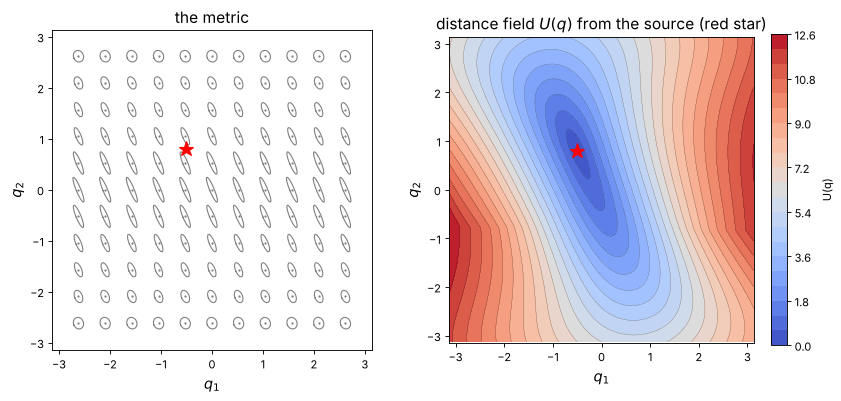

In [4]:
X, Y = sol.grid.X, sol.grid.Y
fig, axs = plt.subplots(1, 2, figsize=(12, 5.2))
P.metric_ellipses(axs[0], G, density=11)
axs[0].plot(*q_s, "r*", ms=14)
P.setup_ax(axs[0], title="the metric")
cf = P.field(axs[1], X, Y, sol.U)
fig.colorbar(cf, ax=axs[1], fraction=0.046, label="U(q)")
axs[1].plot(*q_s, "r*", ms=14)
P.setup_ax(axs[1], title="distance field $U(q)$ from the source (red star)")
plt.show()

The level sets are not circles: they stretch along the cheap directions of the metric.

**Check of the equation.**  We can verify numerically that the field satisfies
$\|\nabla U\|_{G^{-1}}=1$ away from the source (finite differences on the grid).

In [5]:
gnorm = np.sqrt(np.einsum("xyi,xyij,xyj->xy", sol.grad,
                          np.linalg.inv(G(torch.as_tensor(sol.grid.points)).numpy()), sol.grad))
far = sol.U > 0.5
print(f"||grad U||_(G^-1): median {np.median(gnorm[far]):.3f}, "
      f"5-95 % range [{np.percentile(gnorm[far], 5):.3f}, {np.percentile(gnorm[far], 95):.3f}]")

||grad U||_(G^-1): median 1.000, 5-95 % range [0.988, 1.009]


## 3. The geodesic flow and backtracking

The gradient $\nabla U$ is a co-vector; turning it into a velocity requires the metric:

$$V(q)=G(q)^{-1}\,\nabla U(q).$$

$V$ points directly away from the source along the geodesics, and it has unit speed in the
metric: $\|V\|_G^2=\nabla U^\top G^{-1}\nabla U=1$.  So following $-V$ from any $q$,

$$\dot\gamma=-V(\gamma),\qquad \gamma(0)=q,$$

traces the geodesic back to the source, arriving after exactly $U(q)$ units of time.

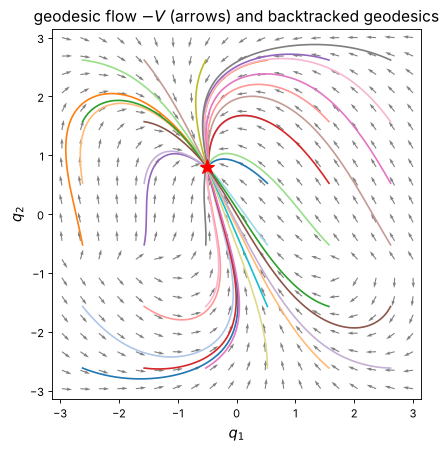

In [6]:
starts = np.array([[a, b] for a in -5 * pi / 6 + np.arange(6) * pi / 3 for b in -5 * pi / 6 + np.arange(6) * pi / 3])
starts = starts[np.linalg.norm(starts - q_s, axis=1) > 0.3]
paths = sol.backtrack(starts, step=0.01)          # all starts integrated together

fig, ax = plt.subplots(figsize=(6, 6))
P.quiver(ax, X, Y, -sol.flow, sub=10, color="gray")
for k, p in enumerate(paths):
    ax.plot(p[:, 0], p[:, 1], color=plt.get_cmap("tab20")(k % 20), lw=1.5)
ax.plot(*q_s, "r*", ms=14)
P.setup_ax(ax, title="geodesic flow $-V$ (arrows) and backtracked geodesics")
plt.show()

The length of each backtracked path equals the value of the field at its start — the
distance field and the geodesics are two views of the same object.

In [7]:
L = np.array([metrics.metric_length(G, torch.as_tensor(p)).item() for p in paths])
for k in range(0, len(starts), 7):
    print(f"start {starts[k].round(2)}   U(start) = {sol.value(starts[k])[0]:6.2f}   "
          f"length of backtracked path = {L[k]:6.2f}")

start [-2.62 -2.62]   U(start) =  10.61   length of backtracked path =  10.62
start [-1.57 -1.57]   U(start) =   8.22   length of backtracked path =   8.22
start [-0.52 -0.52]   U(start) =   2.74   length of backtracked path =   2.73
start [0.52 1.57]   U(start) =   4.92   length of backtracked path =   4.94
start [1.57 2.62]   U(start) =   7.77   length of backtracked path =   7.78


## 4. What a geodesic means for the robot

Let us compare, for one start, the geodesic with the straight line in joint space and look
at the robot motions.  Both connect the same configurations.

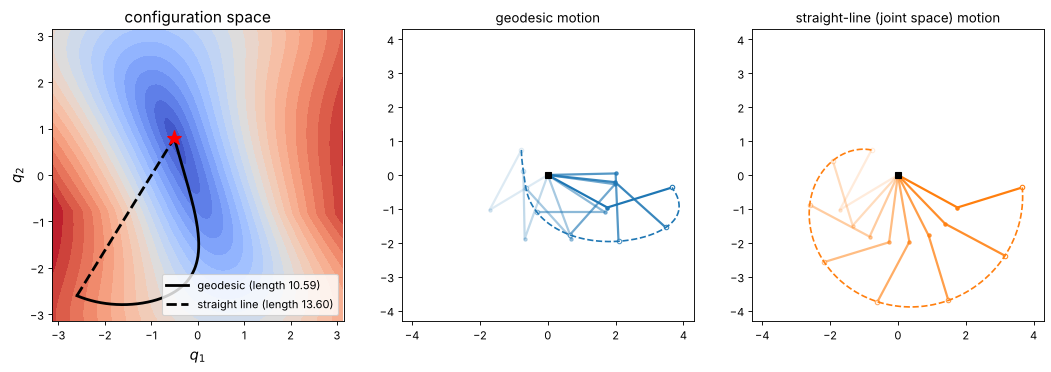

In [8]:
q0 = np.array([-2.6, -2.6])
geo = sol.backtrack(q0, step=0.01)
line = np.linspace(q0, q_s, len(geo))
L_geo = metrics.metric_length(G, torch.as_tensor(geo)).item()
L_line = metrics.metric_length(G, torch.as_tensor(line)).item()

fig, axs = plt.subplots(1, 3, figsize=(16, 5.2))
P.field(axs[0], X, Y, sol.U, lines=False)
axs[0].plot(*geo.T, "k-", lw=2.5, label=f"geodesic (length {L_geo:.2f})")
axs[0].plot(*line.T, "k--", lw=2.5, label=f"straight line (length {L_line:.2f})")
axs[0].plot(*q_s, "r*", ms=14)
axs[0].legend(loc="lower right")
P.setup_ax(axs[0], title="configuration space")
P.arm_motion(axs[1], arm, geo, "tab:blue")
axs[1].set_title("geodesic motion")
P.arm_motion(axs[2], arm, line, "tab:orange")
axs[2].set_title("straight-line (joint space) motion")
plt.show()

The geodesic keeps the elbow folded ($q_2\approx-2.7$, a light, compact arm) while it swings
the shoulder, and opens the elbow only at the end.  It is about 20 % shorter in the
kinetic-energy metric than the straight line, although it looks like a detour in joint space.

## 5. Limits of the grid solver

* **One source at a time.**  The field above answers "how far is every $q$ from $q_s$?".
  For another goal we must solve again (a few seconds here).
* **Grids do not scale.**  A $200^d$ grid is fine for $d=2$ but impossible for a 7-joint arm.
* **Not differentiable** in the source, and only defined at grid points.

The next notebook replaces the grid by a neural network that represents the distance between
*every pair* of configurations.